## **Thông tin bắt buộc**

MSSV:24738801

HoTen:Phan Chi Thanh

SoMay: 37



**số máy chỉ điền 2 con số, vd: 02**

## **Coding 10đ**

* import thư viện

In [131]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt

### **Discovery & Structuring (1.9đ)**


* đọc file csv, in 3 dòng cuối tiên (0.2đ)


In [132]:
df = pd.read_csv("posting2.csv", low_memory=False)
df.tail(3)

,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,...,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
4997,10998357,The National Exemplar,Assitant Restaurant Manager,The National Exemplar is accepting application...,65000.0,YEARLY,"Cincinnati, OH",64896719.0,8.0,NaN,...,We are currently accepting resumes for FOH - A...,1.713278e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,55000.0,45202.0,39061.0
4998,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,175000.0,YEARLY,"New Hyde Park, NY",766262.0,16.0,NaN,...,This position requires a baseline understandin...,1.712896e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,157500.0,11040.0,36059.0
4999,35982263,NaN,Service Technician (duplicate job_id),Looking for HVAC service tech with experience ...,80000.0,YEARLY,"Burlington, IA",NaN,3.0,NaN,...,NaN,1.713452e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,70000.0,52601.0,19057.0


* đọc thông tin data (0.15đ)

In [133]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 31 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   job_id                      5000 non-null   int64  
 1   company_name                4931 non-null   str    
 2   title                       5000 non-null   str    
 3   description                 5000 non-null   str    
 4   max_salary                  1196 non-null   float64
 5   pay_period                  1442 non-null   str    
 6   location                    5000 non-null   str    
 7   company_id                  4931 non-null   float64
 8   views                       4943 non-null   float64
 9   med_salary                  246 non-null    float64
 10  min_salary                  1196 non-null   float64
 11  formatted_work_type         5000 non-null   str    
 12  applies                     947 non-null    float64
 13  original_listed_time        5000 non-null   

* in thông tin số dòng và số cột (0.15đ)

In [134]:
print("so dong la", df.shape[0])
print("so cot la", df.shape[1])

so dong la 5000
so cot la 31


* in ra các giá trị formatted_work_type trong bộ data (0.15đ)

In [135]:
df['formatted_work_type']

0       Full-time
1       Full-time
2       Full-time
3       Full-time
4       Full-time
          ...    
4995    Full-time
4996    Full-time
4997    Full-time
4998    Full-time
4999    Full-time
Name: formatted_work_type, Length: 5000, dtype: str

* đổi tên cột normalized_salary --> salary và formatted_experience_level --> experience_level (0.2đ)

In [136]:
df.rename(columns= {
     'normalized_salary': 'salary' ,
       'formatted_experience_level': 'experience_level'
}, inplace=True)

* in lại danh sách các cột sau khi rename (0.15đ)

In [137]:
df.columns.tolist()

['job_id',
 'company_name',
 'title',
 'description',
 'max_salary',
 'pay_period',
 'location',
 'company_id',
 'views',
 'med_salary',
 'min_salary',
 'formatted_work_type',
 'applies',
 'original_listed_time',
 'remote_allowed',
 'job_posting_url',
 'application_url',
 'application_type',
 'expiry',
 'closed_time',
 'experience_level',
 'skills_desc',
 'listed_time',
 'posting_domain',
 'sponsored',
 'work_type',
 'currency',
 'compensation_type',
 'salary',
 'zip_code',
 'fips']

* Tạo dataframe df_profile bao gồm dtype, nunique, missing_count, missing_percentage. Sắp xếp giảm dần theo missing_percentage. (0.5đ)


In [138]:
type =  df.dtypes
nun = df.nunique()
misscout = df.isnull().sum()
missper =(df.isnull().sum() / len(df) )* 100
df_profile = pd.DataFrame({
    'dtype': type,
    'nunique' : nun,
    'missing_count':misscout,
    'missing_percentage': missper
})
df_profile = (df_profile.sort_values(by='missing_percentage', ascending=False).reset_index(drop=True))
df_profile

,dtype,nunique,missing_count,missing_percentage
0,float64,39,4959,99.18
1,str,114,4880,97.60
2,float64,147,4754,95.08
3,float64,1,4341,86.82
4,float64,73,4053,81.06
5,float64,488,3804,76.08
6,float64,532,3804,76.08
7,str,1,3558,71.16
8,str,1,3558,71.16
9,str,4,3558,71.16


* tìm số dòng thỏa điều kiện formatted_work_type là Full-time và salary từ 100000 trở lên (0.2đ)

In [139]:
df[(df['formatted_work_type'] =='Full-time') & (df['salary'] > 100000)]

,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,...,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,salary,zip_code,fips
3,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,175000.0,YEARLY,"New Hyde Park, NY",766262.0,16.0,NaN,...,This position requires a baseline understandin...,1.712896e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,157500.0,11040.0,36059.0
14,3619548798,"Dexterity, Inc.",Senior Mechanical Engineer,Senior Mechanical Engineer\nLocation: Redwood ...,190000.0,YEARLY,"Redwood City, CA",28173564.0,3.0,NaN,...,NaN,1.712885e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,170000.0,94061.0,6081.0
58,3884433957,Vaco,HRIS Analyst,***HRIS Analyst***\n***Remote Position***\n***...,NaN,HOURLY,"Atlanta, GA",11229.0,34.0,57.0,...,NaN,1.712349e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,118560.0,30303.0,13121.0
60,3884434376,Tandym Group,General Dermatologist,A health services organization in Ohio is curr...,575000.0,YEARLY,"Akron, OH",86041588.0,5.0,NaN,...,NaN,1.712348e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,557500.0,44301.0,39153.0
64,3884435101,Ledgent Technology,Sr. .NET Developer (BOCA RATON),Ledgent Technology is actively seeking a seaso...,140000.0,YEARLY,"Boca Raton, FL",10592585.0,26.0,NaN,...,NaN,1.712346e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,125000.0,33428.0,12099.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4952,3906256394,Circle,Senior Enablement Lead,Circle is a financial technology company at th...,120000.0,YEARLY,"Boston, MA",3509899.0,3.0,NaN,...,NaN,1.713568e+12,boards.greenhouse.io,0,FULL_TIME,USD,BASE_SALARY,105000.0,2108.0,25025.0
4965,3906258119,TD,Sr Audit Group Manager Retail Distribution,Work Location:\n\nMt Laurel - Operations Cente...,183460.0,YEARLY,"Laurel, MT",2775.0,5.0,NaN,...,NaN,1.713568e+12,td.wd3.myworkdayjobs.com,0,FULL_TIME,USD,BASE_SALARY,148180.0,59044.0,30111.0
4987,3906260144,Sterling Engineering,Operations Manager,Overview/Summary:Join a dynamic and innovative...,135000.0,YEARLY,Kansas City Metropolitan Area,24211.0,NaN,NaN,...,NaN,1.713567e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,127500.0,NaN,NaN
4989,3906261027,Cisco,Solutions Engineer,"Why you'll love Cisco\n\nWe change the World, ...",236800.0,YEARLY,"Herndon, VA",1063.0,4.0,NaN,...,NaN,1.713568e+12,jobs.cisco.com,0,FULL_TIME,USD,BASE_SALARY,210850.0,20170.0,NaN


* cho biết số dòng có remote_allowed bằng 1 và application_type là OffsiteApply (0.2đ)

In [140]:
teo = df[(df['remote_allowed'] == 1) & (df['application_type'] == 'OffsiteApply')]
print('so dong ', teo.shape[0])

so dong  306


### **Cleaning**

#### **Duplicated & missing data (3.05đ)**


Duplicate count (0.4đ)
* In số dòng trùng cả bản ghi.
* In số job_id bị lặp.


In [141]:

print("so dong trung ", df.duplicated().shape[0])
print("so job bi lap ", df['job_id'].duplicated().shape[0])

so dong trung  5000
so job bi lap  5000


* xoá số dòng duplicated cả bản ghi (0.25đ)


In [142]:
df = df.drop_duplicates(df)
df.shape

(4997, 31)

* xoá số dòng duplicated số job_id (0.25đ)


In [143]:

df = df.drop_duplicates(subset=["job_id"])
df.shape

# df[dsa l] = df .isna. f kieu int 

(4995, 31)

df2 missing table (0.4đ)
* Kiểm tra dữ liệu có missing không?
* Nếu có, tạo df2 gồm 3 cột: column_name, missing_count, missing_percentage
* Sắp xếp df2 giảm dần theo missing_count
* Chỉ giữ các dòng có missing_count khác 0

In [144]:
# df2 =?
miss_cout = df.isnull().sum()
miss_per =(df.isnull().mean())* 100
df2 = pd.DataFrame ({'columns_name' : df.columns,
                     'missing_count': miss_cout,
                     "missing_percent": miss_per} )

df2 = (df2[df2['missing_count'] > 0].sort_values(ascending=False, by='missing_count').reset_index(drop=True))
df2


,columns_name,missing_count,missing_percent
0,closed_time,4954,99.179179
1,skills_desc,4878,97.657658
2,med_salary,4749,95.075075
3,remote_allowed,4336,86.806807
4,applies,4049,81.061061
5,max_salary,3804,76.156156
6,min_salary,3804,76.156156
7,compensation_type,3558,71.231231
8,pay_period,3558,71.231231
9,currency,3558,71.231231


Missing-value bar chart (0.4đ)
* Sử dụng barchart để vẽ df2 với x là missing_count, y là column_name. Trong đó xlabel là số lượng thiếu, ylabel là tên cột

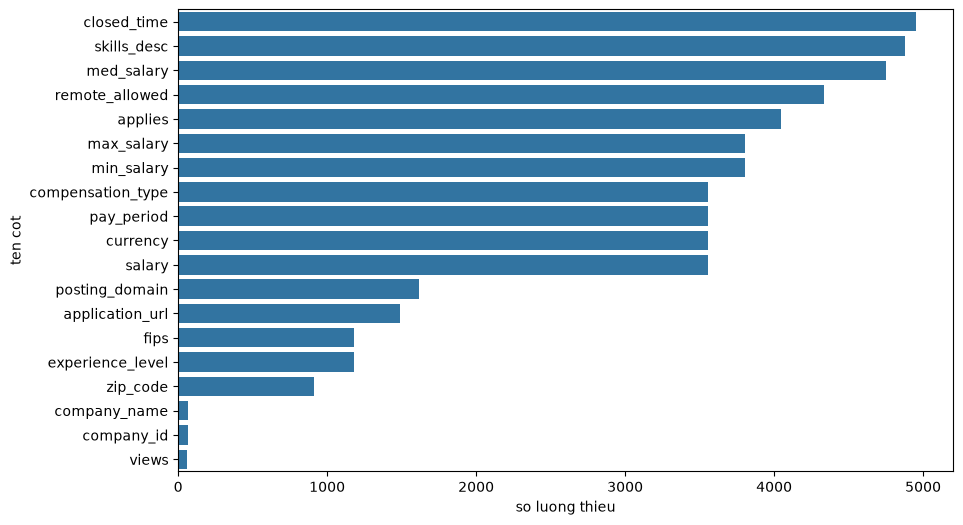

In [145]:
import matplotlib.pyplot as plt
plt.figure( figsize = (10, 6))
sns.barplot(
    data=df2,
    x = 'missing_count',
    y = 'columns_name'
)
plt.xlabel('so luong thieu')
plt.ylabel("ten cot")
plt.show()

* tạo ra 1 cột salary_missing, nếu salary bị thiếu thì bằng 1, ngược lại bằng 0, gợi ý isna() (0.25đ)


In [146]:
df['salary_missing'] =df['salary'].isna().astype(int)
df['salary_missing']

0       0
1       0
2       0
3       0
4       0
       ..
4990    1
4991    1
4992    1
4993    1
4994    0
Name: salary_missing, Length: 4995, dtype: int64

* salary_missing_by_work = Nhóm theo formatted_work_type, tính mean của cột salary_missing rồi nhân 100 để ra tỷ lệ thiếu (%). Sắp xếp tăng dần và đổi tên thành salary_missing_pct. (0.25đ)


In [147]:
df.columns

Index(['job_id', 'company_name', 'title', 'description', 'max_salary',
       'pay_period', 'location', 'company_id', 'views', 'med_salary',
       'min_salary', 'formatted_work_type', 'applies', 'original_listed_time',
       'remote_allowed', 'job_posting_url', 'application_url',
       'application_type', 'expiry', 'closed_time', 'experience_level',
       'skills_desc', 'listed_time', 'posting_domain', 'sponsored',
       'work_type', 'currency', 'compensation_type', 'salary', 'zip_code',
       'fips', 'salary_missing'],
      dtype='str')

In [148]:
# salary_missing_by_work =?
salary_missing_by_work  = df.groupby('formatted_work_type')['salary_missing'].mean()*100
salary_missing_by_work = salary_missing_by_work.sort_values().rename('salary_missing_pct')

* Vẽ bar chart tỷ lệ thiếu salary theo formatted_work_type. xlabel là tỷ lệ thiếu (%), ylabel là tên nhóm. (0.25đ)


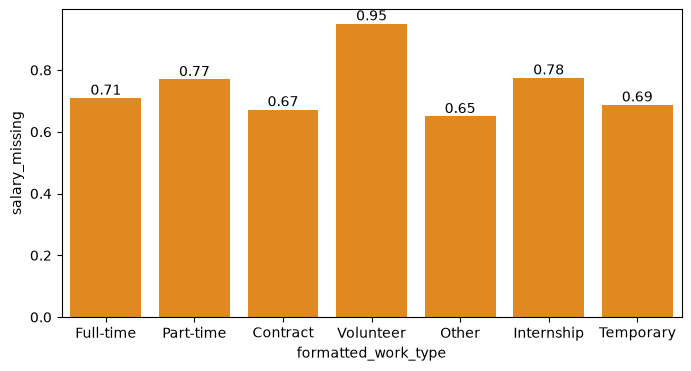

In [149]:
plt.figure(figsize=(8, 4))

ax = sns.barplot(
    data=df,
    x='formatted_work_type',
    y='salary_missing',
    color="darkorange",
    errorbar=None  
)

ax.bar_label(ax.containers[0], fmt='%.2f')
plt.show()

Fill with mode/mean/median (0.6đ)
* company_name: điền mode.
* views và applies: điền median.
* experience_level: ô trống điền nhãn Unknown.
* Tạo remote_flag từ remote_allowed, ô trống điền 0.
* salary: không điền.


In [150]:
# df['company_name'] = df['company_name'].fillna(df['company_name'].mode().iloc[0])
# df['views'] = df['views'].fillna(df['views'].median())
# df['applies'] = df['applies'].fillna(df['applies'].median())
# df  =               df.fillna(value = {'experience_level':'Unknown'})
# df = df.fillna(value = {'remote_allowed': '0'})
# df['remote_flag']  = df['remote_allowed']
# df= df.dropna(subset = ['salary'])


In [151]:
mode_company = df['company_name'].mode()[0]
df['company_name'] = df['company_name'].fillna(mode_company)
df['views'] = df['views'].fillna(df['views'].median())
df['applies'] = df['applies'].fillna(df['applies'].median())
df['experience_level'] = df['experience_level'].fillna("Unknown")
df['remote_flag'] = df['remote_allowed'].fillna(0)


In [152]:
# kiểm tra lại sau xử lý missing data
df[["company_name", "views", "applies", "experience_level", "salary"]].isnull().sum()

company_name           0
views                  0
applies                0
experience_level       0
salary              3558
dtype: int64

#### **Outlier (2.5đ)**

* df2_1 chỉ chứa views và salary. Hiển thị 2 dòng (0.2đ)


In [153]:
df2_1 = df[['views','salary']]
df2_1.head(2)


,views,salary
0,20.0,38480.0
1,1.0,83200.0


df3 with concat (0.5đ)
* Tạo dataframe df3 bằng CONCAT
* df3 gồm các cột Q1, Q3, IQR, lower_bound, upper_bound, outlier_count
* Trong đó cột Q1 là 22%, Q3 = 78%

In [154]:
# df3 = ?

df = df.select_dtypes('number')
q1 = df.quantile(0.22)
q3 = df.quantile(0.78)
iqr = q3 - q1
lowerr = q1 - 1.5 * iqr
upperr = q3 +1.5 * iqr
oulierr = ((df> upperr) | (df < lowerr)).sum()
df3 = pd.concat([q1, q3, iqr, lowerr, upperr, oulierr], axis=1)
df3.columns = ["Q1", "Q3", "IQR", "lower_bound", "upper_bound", "oulier_count"]
df3


,Q1,Q3,IQR,lower_bound,upper_bound,oulier_count
job_id,3.891082e+09,3.904947e+09,1.386433e+07,3.870286e+09,3.925743e+09,30
max_salary,4.461600e+01,1.500000e+05,1.499554e+05,-2.248885e+05,3.749331e+05,12
company_id,1.100514e+04,1.087712e+07,1.086612e+07,-1.628817e+07,2.717630e+07,761
views,3.000000e+00,8.000000e+00,5.000000e+00,-4.500000e+00,1.550000e+01,689
med_salary,1.800000e+01,3.711270e+04,3.709470e+04,-5.562406e+04,9.275476e+04,19
min_salary,3.298000e+01,1.100000e+05,1.099670e+05,-1.649175e+05,2.749505e+05,7
applies,3.000000e+00,3.000000e+00,0.000000e+00,3.000000e+00,3.000000e+00,864
original_listed_time,1.712794e+12,1.713484e+12,6.903324e+08,1.711758e+12,1.714519e+12,70
remote_allowed,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0
expiry,1.715454e+12,1.716094e+12,6.399411e+08,1.714494e+12,1.717054e+12,172


df4 outlier filter (0.4đ)
* df4 lọc lại dữ liệu, loại các dòng có ít nhất một cột số trong df2_1 nằm ngoài [lower_bound, upper_bound]

In [155]:
# df4 =?
df4  = df.copy()
df4 = df[((df >= lowerr) & (df <= upperr)).any(axis = 1)]

In [156]:
df4.shape


(4995, 18)

df5 clip (0.3đ)
* Tạo df5 từ df bằng clip kéo ngưỡng về chặn trên chặn dưới

In [157]:
df5 = df.copy()
df5=df5.clip(upper= upperr, lower= lowerr, axis=1)

In [158]:
df5.shape


(4995, 18)

In [159]:
df4

,job_id,max_salary,company_id,views,med_salary,min_salary,applies,original_listed_time,remote_allowed,expiry,closed_time,listed_time,sponsored,salary,zip_code,fips,salary_missing,remote_flag
0,921716,20.0,2774458.0,20.0,NaN,17.0,2.0,1.713398e+12,NaN,1.715990e+12,NaN,1.713398e+12,0,38480.0,8540.0,34021.0,0,0.0
1,1829192,50.0,NaN,1.0,NaN,30.0,3.0,1.712858e+12,NaN,1.715450e+12,NaN,1.712858e+12,0,83200.0,80521.0,8069.0,0,0.0
2,10998357,65000.0,64896719.0,8.0,NaN,45000.0,3.0,1.713278e+12,NaN,1.715870e+12,NaN,1.713278e+12,0,55000.0,45202.0,39061.0,0,0.0
3,23221523,175000.0,766262.0,16.0,NaN,140000.0,3.0,1.712896e+12,NaN,1.715488e+12,NaN,1.712896e+12,0,157500.0,11040.0,36059.0,0,0.0
4,35982263,80000.0,NaN,3.0,NaN,60000.0,3.0,1.713452e+12,NaN,1.716044e+12,NaN,1.713452e+12,0,70000.0,52601.0,19057.0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4990,3906261328,NaN,27139071.0,4.0,NaN,NaN,3.0,1.713570e+12,NaN,1.716163e+12,NaN,1.713571e+12,0,NaN,60073.0,17097.0,1,0.0
4991,3906263301,NaN,413796.0,4.0,NaN,NaN,3.0,1.713571e+12,NaN,1.716164e+12,NaN,1.713572e+12,0,NaN,NaN,NaN,1,0.0
4992,3906265259,NaN,16243953.0,4.0,NaN,NaN,3.0,1.713572e+12,NaN,1.716164e+12,NaN,1.713572e+12,0,NaN,16689.0,42057.0,1,0.0
4993,3906266217,NaN,6404239.0,1.0,NaN,NaN,3.0,1.713571e+12,1.0,1.716163e+12,NaN,1.713571e+12,0,NaN,NaN,NaN,1,1.0


Histogram of salary (0.25đ)
* vẽ histogram cho cột salary trong df4
* title là "phân phối salary"
* xlabel là "salary (USD/year)"

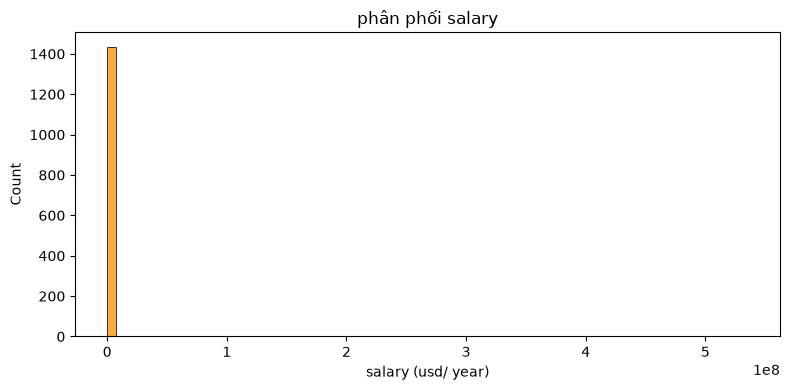

In [160]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df4, x='salary', color='darkorange')
plt.title("phân phối salary")

plt.tight_layout()
plt.xlabel("salary (usd/ year)")
plt.show()

Is salary skewed? Print skew, kurtosis, mean, median (0.6đ)
* Dùng cột salary của df4 (bỏ giá trị thiếu). Dữ liệu có lệch không? In ra skew, kurtosis, mean, median.
* Từ kurtosis, so với phân phối chuẩn thì đỉnh nhọn hơn hay hai đuôi dày hơn?

In [161]:
sala = df4['salary']
print("skew", sala.skew())
print("kurtosis", sala.kurtosis())
print("mean", sala.mean())
print("median", sala.median())
# du lieu lech phai, duoi ve phia gia tri lon va phan phoi dinh nhon hon

skew 35.45718979140207
kurtosis 1296.3292308318435
mean 557609.5553723034
median 83200.0


Gợi ý trả lời (tự điền theo số vừa in, không chép kết luận):

1. Xem dấu của skew. skew > 0 thì lệch phải, đuôi về phía giá trị lớn; skew < 0 thì lệch trái. Đối chiếu mean với median: bên nào lớn hơn thì đuôi kéo về bên đó.

2. kurtosis của pandas là excess kurtosis. Phân phối chuẩn có excess kurtosis bằng 0. Số vừa in > 0 thì đỉnh nhọn hơn và hai đuôi dày hơn chuẩn; < 0 thì đỉnh phẳng hơn và hai đuôi mỏng hơn chuẩn.

Create salary_log with np.log (0.25đ)

* Tạo cột salary_log trong df4 bằng np.log.
* salary không dương thì salary_log để NaN.
* Gợi ý: tạo cột salary_log toàn NaN trước. Dùng .loc với điều kiện salary > 0 rồi mới gán np.log. np.log chỉ nhận số dương.


In [162]:
df4 = df.copy()
df4['salary_log'] = np.nan
df4.loc[df4["salary"] > 0, "salary_log"] = np.log(
    df4.loc[df4["salary"] > 0, "salary"]
)

### **Univariate Analysis (0.55đ)**


* thống kê mô tả cho 2 cột salary và salary_log trong df4 (0.3đ)

In [163]:
df4['salary'].describe()

df4['salary_log'].describe()

count    1435.000000
mean       11.270642
std         0.984505
min         3.068053
25%        10.866471
50%        11.329003
75%        11.773363
max        20.098898
Name: salary_log, dtype: float64

* In skew, kurtosis, mean, median của salary_log. Vẽ hai histogram cạnh nhau: salary và salary_log. (0.25đ)


salary_log skew: -3.3747016442185425
salary_log kurtosis: 36.878153286052076
salary_log mean: 11.27064226265231
salary_log median: 11.3290026268093


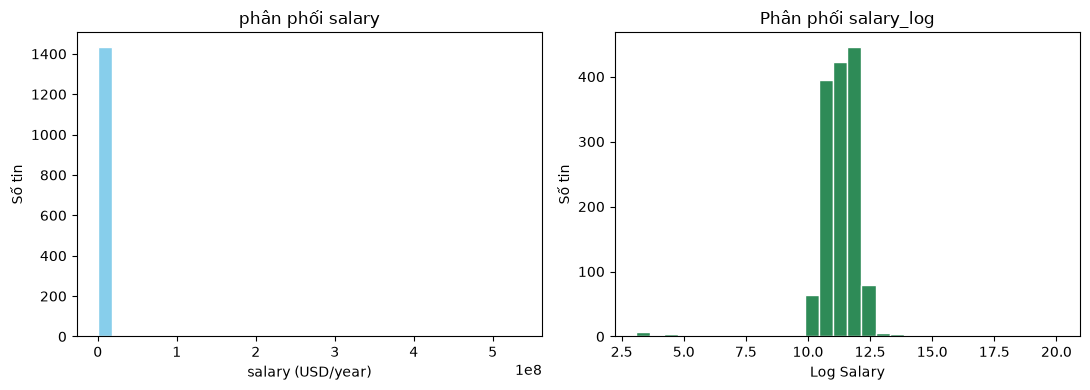

In [164]:
print("salary_log skew:", df4['salary_log'].skew())
print("salary_log kurtosis:", df4['salary_log'].kurtosis())
print("salary_log mean:",  df4['salary_log'].mean())
print("salary_log median:",  df4['salary_log'].median())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df4["salary"].dropna(), bins=30, color='skyblue', edgecolor='white')
axes[0].set_title("phân phối salary")
axes[0].set_xlabel("salary (USD/year)")

# salary_log tương tự salary
# axes[1].
axes[1].hist(
    df4["salary_log"].dropna(), bins=30, color="seagreen", edgecolor="white"
)
axes[1].set_title("Phân phối salary_log")
axes[1].set_xlabel("Log Salary")

for ax in axes:
    ax.set_ylabel("Số tin")
    
plt.tight_layout()
plt.show()

### **Bivariate & Multivariate Analysis (1.65đ)**

Xem mối quan hệ giữa các biến.

* Heatmap (0.3đ): Correlation heatmap giữa các cột số, bao gồm views, applies, min_salary, max_salary, med_salary, salary.

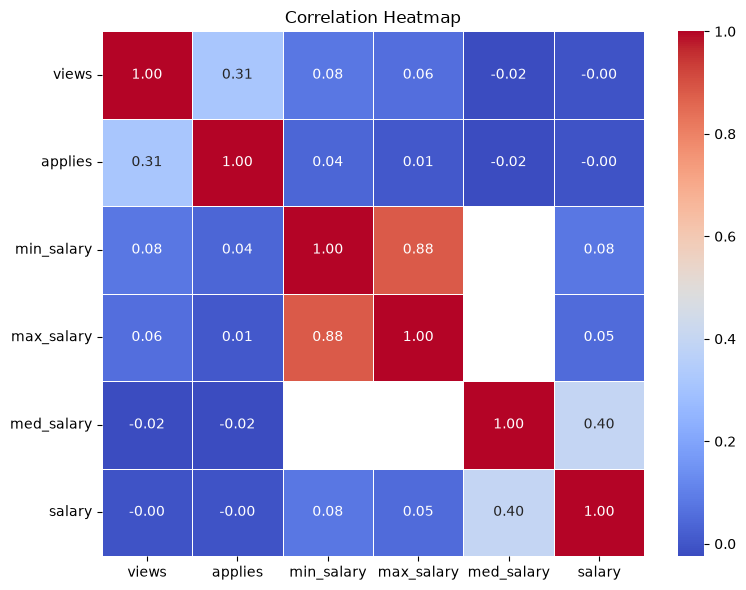

In [165]:
num_cols = ['views', 'applies', 'min_salary', 'max_salary', 'med_salary', 'salary']
valid_num_cols = [col for col in num_cols if col in df4.columns]
plt.figure(figsize=(8, 6))
sns.heatmap(
    df4[valid_num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [166]:
df4.columns

Index(['job_id', 'max_salary', 'company_id', 'views', 'med_salary',
       'min_salary', 'applies', 'original_listed_time', 'remote_allowed',
       'expiry', 'closed_time', 'listed_time', 'sponsored', 'salary',
       'zip_code', 'fips', 'salary_missing', 'remote_flag', 'salary_log'],
      dtype='str')

In [167]:
import numpy as np

# Tính IQR trên các cột số
num_cols = df.select_dtypes(include=["number"]).columns
q1 = df[num_cols].quantile(0.25)
q3 = df[num_cols].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Lọc Outlier cho views và salary nhưng GIỮ NGUYÊN tất cả các cột của df
cond_views = (df["views"] >= lower_bound["views"]) & (
    df["views"] <= upper_bound["views"]
)
cond_salary = (df["salary"] >= lower_bound["salary"]) & (
    df["salary"] <= upper_bound["salary"]
)

df4 = df[cond_views & cond_salary].copy()

# Tạo lại cột salary_log cho df4
df4["salary_log"] = np.nan
df4.loc[df4["salary"] > 0, "salary_log"] = np.log(
    df4.loc[df4["salary"] > 0, "salary"]
)

In [168]:
print(df.columns.tolist())

['job_id', 'max_salary', 'company_id', 'views', 'med_salary', 'min_salary', 'applies', 'original_listed_time', 'remote_allowed', 'expiry', 'closed_time', 'listed_time', 'sponsored', 'salary', 'zip_code', 'fips', 'salary_missing', 'remote_flag']


In [169]:
df4.columns

Index(['job_id', 'max_salary', 'company_id', 'views', 'med_salary',
       'min_salary', 'applies', 'original_listed_time', 'remote_allowed',
       'expiry', 'closed_time', 'listed_time', 'sponsored', 'salary',
       'zip_code', 'fips', 'salary_missing', 'remote_flag', 'salary_log'],
      dtype='str')

* df4 group by theo formatted_work_type, tính count, mean, median của salary (0.3đ), gợi ý: .agg([count,...])


In [170]:
df4.groupby("formatted_work_type")["salary"].agg(["count", "mean", "median"])

KeyError: 'formatted_work_type'

* df4 group by theo experience_level, tính count, mean, median của salary. (0.5đ)


* Tạo pivot median salary theo experience_level (hàng) và formatted_work_type (cột). Vẽ heatmap. (0.55đ). Gợi ý: dùng pivot_table, index là hàng, columns là cột, values, aggfunc gọi hàm. Sau đó vẽ heatmap


In [ ]:
# salary_pivot = ?

# plt.figure(?)
# sns.heatmap(salary_pivot, annot=True, fmt=".0f", cmap="YlGnBu")
# plt.title("")
# plt.xlabel("")
# plt.ylabel("")
# plt.tight_layout()
# plt.show()

### **Publishing (0.35đ)**

* Lưu df4 ra file Excel, đặt tên df4.xlsx (0.2đ)

Không ghi các cột description, skills_desc, job_posting_url, application_url.


In [ ]:
df4.to_csv("df4.xlsx")

* Sau đó lưu df4 ra file HTML, đặt tên df4.html (0.15đ)

Không ghi các cột description, skills_desc, job_posting_url, application_url.


In [ ]:
df4.to_csv("df4.html")